In [ ]:
#Hector Pons Castellano Lab3

Algoritmo trapecio: 46.12 metros
Funcion predeterminada: 46.12 metros


/var/folders/mk/w5yc3fvd26b_94wfxv7gft7w0000gn/T/ipykernel_15958/2890154799.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


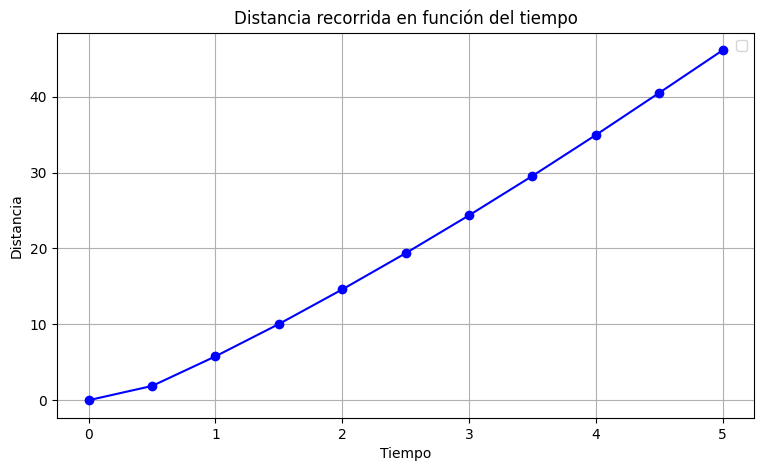

In [31]:
#Ejercicio 1
import numpy as np
import matplotlib.pyplot as plt

#datos de la tabla
t = np.array([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0])
v = np.array([0, 7.51, 8.10, 8.93, 9.32, 9.76, 10.22, 10.56, 11.01, 11.22, 11.22])

#calculamos el tamaño h
h = t[1] - t[0] 

# Algoritmo trapecio para aproximacion numerica
distancia_manual = h * (0.5 * v[0] + np.sum(v[1:-1]) + 0.5 * v[-1])
print("Algoritmo trapecio:", distancia_manual, "metros")

#duncion predeterminada
distancia_numpy = np.trapezoid(v, t)
print("Funcion predeterminada:", distancia_numpy, "metros")

distancia_acumulada = np.zeros(len(t))
suma = 0 

#calculamos area trapecio
for i in range(len(t) - 1):
    area_paso = h * (v[i] + v[i+1]) / 2
    suma = suma + area_paso
    distancia_acumulada[i + 1] = suma

#grafica
plt.figure(figsize=(9, 5))
plt.plot(t, distancia_acumulada, color='blue', marker='o', linestyle='-')
plt.title('Distancia recorrida en función del tiempo')
plt.xlabel('Tiempo')
plt.ylabel('Distancia')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
#Ejercicio 2
import numpy as np
import scipy.integrate as spi

#derivada de f(t)
def f_prima(t):
    return (-8 * t / np.sqrt(2 * np.pi)) * np.exp(-4 * t**2)


#definimos la funcion a integrar
def integrar(t):
    return np.sqrt(1 + f_prima(t)**2)

#limites integradcion
a = -2
b = 2

#con scipy calculamos la integral exacta
longitud, error = spi.quad(integrar, a, b)

# Mostramos los resultados por pantalla
print("s(x):", longitud)
print("Error:", error)

s(x): 4.185235675527371
Error: 1.2274375647418389e-09



Funcion A:
Exacto: 27.0282

h=2
P.Medio: 15.9744
Trapecio: 51.3025
np.trapezoid: 51.3025

h=1
P.Medio: 23.7968
Trapecio: 33.6385
np.trapezoid: 33.6385

h=0.1
P.Medio: 26.9942
Trapecio: 27.0963
np.trapezoid: 27.0963

h=0.01
P.Medio: 27.0279
Trapecio: 27.0289
np.trapezoid: 27.0289


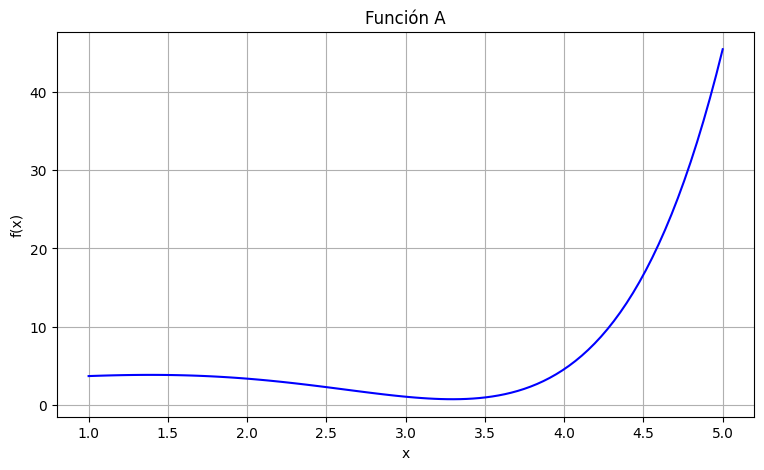


Funcion B:
Exacto: 44.1056

h=2
P.Medio: 43.9192
Trapecio: 44.1742
np.trapezoid: 44.1742

h=1
P.Medio: 44.1388
Trapecio: 44.0467
np.trapezoid: 44.0467

h=0.1
P.Medio: 44.1059
Trapecio: 44.1051
np.trapezoid: 44.1051

h=0.01
P.Medio: 44.1056
Trapecio: 44.1056
np.trapezoid: 44.1056


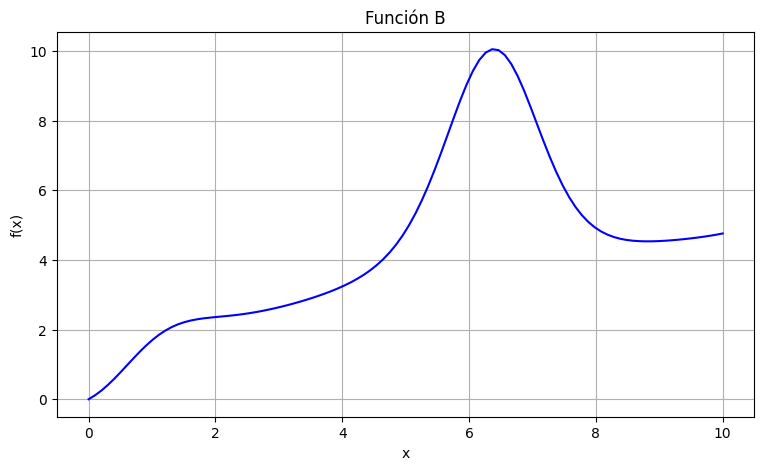


Funcion C:
Exacto: 24.4294

h=2
P.Medio: 19.8513
Trapecio: 35.1966
np.trapezoid: 35.1966

h=1
P.Medio: 22.9561
Trapecio: 27.5240
np.trapezoid: 27.5240

h=0.1
P.Medio: 24.4129
Trapecio: 24.4624
np.trapezoid: 24.4624

h=0.01
P.Medio: 24.4292
Trapecio: 24.4297
np.trapezoid: 24.4297


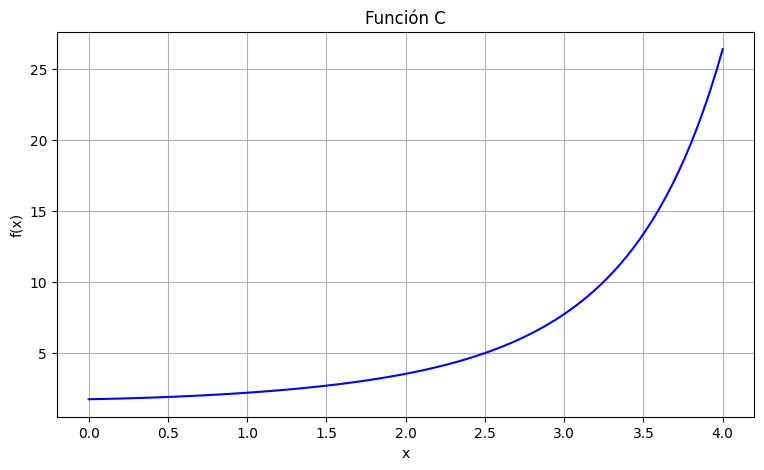


Funcion D:
Exacto: 59.8140

h=2
P.Medio: 133.5124
Trapecio: -55.4486
np.trapezoid: -58.0657

h=1
P.Medio: 69.2426
Trapecio: 33.9844
np.trapezoid: 35.5884

h=0.1
P.Medio: 59.1162
Trapecio: 58.8127
np.trapezoid: 59.6018

h=0.01
P.Medio: 59.7847
Trapecio: 59.7816
np.trapezoid: 59.8120


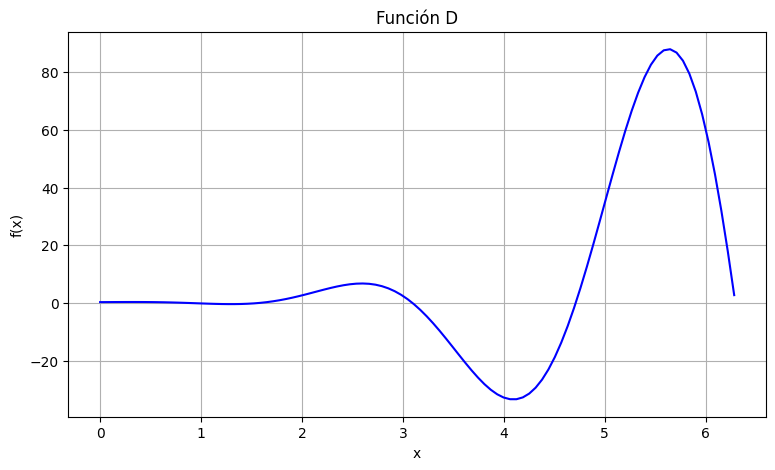

In [45]:
import numpy as np
import scipy.integrate as spi
import matplotlib.pyplot as plt

#definimos los algoritmos
def punto_medio(f, a, b, h):
    n = int((b - a) / h)
    x_medio = np.linspace(a + h/2, b - h/2, n)
    return h * np.sum(f(x_medio))

def trapecio_compuesto(f, a, b, h):
    n = int((b - a) / h)
    x = np.linspace(a, b, n + 1)
    return h * (0.5 * f(a) + np.sum(f(x[1:-1])) + 0.5 * f(b))


#dunciones y sus limites
def fA(x): 
    return np.exp(x) - x**3 + x**2 - x + 2
aA, bA = 1, 5

def fB(x): 
    x = np.maximum(x, 1e-10) # Evita división por cero / errores de límite
    return x**np.cos(x) + np.log(x**2 + 1)
aB, bB = 0, 10

def fC(x): 
    return 3**((2 + x)**(np.log(x + 1) - 1))
aC, bC = 0, 4

def fD(x): 
    return np.cos(x) * (np.log10(1 + np.exp(x)) - x**3 * np.sin(x))
aD, bD = 0, 2 * np.pi

funciones = [fA, fB, fC, fD]
limites = [(aA, bA), (aB, bB), (aC, bC), (aD, bD)]
pasos = [2, 1, 0.1, 0.01]
nombres = ['A', 'B', 'C', 'D']


#calculamos y las sacamos por grafica
for i in range(4):
    f = funciones[i]
    a = limites[i][0]
    b = limites[i][1]
    letra = nombres[i]
    
    print(f"\nFuncion {letra}:")
    
    #calculo SciPy
    exacto, error = spi.quad(f, a, b)
    print(f"Exacto: {exacto:.4f}")
    
    for h in pasos:
        pm = punto_medio(f, a, b, h)
        tc = trapecio_compuesto(f, a, b, h)
        
        #funcion predeterminada NumPy
        n = int((b - a) / h)
        x_np = np.linspace(a, b, n + 1)
        trap_np = np.trapezoid(f(x_np), x_np)
        

        print(f"\nh={h}")
        print(f"P.Medio: {pm:.4f}")
        print(f"Trapecio: {tc:.4f}")
        print(f"np.trapezoid: {trap_np:.4f}")

    plt.figure(figsize=(9, 5))
    x_plot = np.linspace(a, b, 100)
    y_plot = f(x_plot)
    plt.plot(x_plot, y_plot, color='blue')
    plt.title(f"Función {letra}")
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.grid(True)
    plt.show()

In [50]:
#Ejercicio 4
import numpy as np
import scipy.integrate as scipy_integrate

#integral doble
def funcion_integral_doble_a(x, y):
    return np.cos(x) * np.sqrt(1 + np.cos(x)**2)

resultado_a, error_a = scipy_integrate.dblquad(funcion_integral_doble_a, 0, 1, lambda y: np.arctan(y), lambda y: np.pi/2)


#area entre dos curvas
def funcion_area_b(y, x):
    return 1

resultado_b, error_b = scipy_integrate.dblquad(funcion_area_b, 0, np.pi/2, lambda x: np.sin(x), lambda x: np.sin(x) + 1)


#integral triple
def funcion_integral_triple_c(x, y, z):
    return z * (2**(x - y))

resultado_c, error_c = scipy_integrate.tplquad(funcion_integral_triple_c, 0, 1, lambda z: 0, lambda z: 1, lambda z, y: -2, lambda z, y: 1)


#itegral triple cilindrica
def funcion_integral_triple_d(z, r, theta):
    return (r**3) * (np.cos(theta)**2)

resultado_d, error_d = scipy_integrate.tplquad(funcion_integral_triple_d, 0, 2*np.pi, lambda theta: 0, lambda theta: 3, lambda theta, r: 0, lambda theta, r: 9 - r**2)

print(f"Integral A: {resultado_a:.4f}")
print(f"Integral B: {resultado_b:.4f}")
print(f"Integral C: {resultado_c:.4f}")
print(f"Integral D: {resultado_d:.4f}")

Integral A: 0.7143
Integral B: 1.5708
Integral C: 0.9106
Integral D: 190.8518


In [62]:
import numpy as np
from scipy.optimize import fsolve
import sympy as sp

#sistema lineal
def resolver_sistema_lineal(a, b, c, d, e, f):
    determinante = (a * e) - (b * d)
    if determinante == 0:
        print("El sistema no tiene solución única.")
    else:
        x = ((c * e) - (b * f)) / determinante
        y = ((a * f) - (c * d)) / determinante
        print(f"Solución: x = {x}, y = {y}")

print("sistemas lineal:")
resolver_sistema_lineal(6, -5, 8, -12, 2, 0)
resolver_sistema_lineal(2, 3, 20, 7, 2, 53)
resolver_sistema_lineal(10, 2, 16, 5, 1, 8)

#sistema no lineales
print("\nsistema no lineal:")

#sistemas para SciPy
def sistema_1(vars):
    x, y = vars
    return [x**2 + y**2 - 10, x**2 - y**2 - 4]

def sistema_2(vars):
    x, y = vars
    return [x**3 + y**3 - 9, x**2 + y**2 - 5]

def sistema_3(vars):
    x, y = vars
    return [np.sin(x) + np.cos(y) - 1, x**2 + y**2 - 1]

# Resolver con SciPy
print("SciPy sistema 1:", fsolve(sistema_1, [1, 1]))
print("SciPy sistema 2:", fsolve(sistema_2, [1, 1]))
print("SciPy sistema 3:", fsolve(sistema_3, [0.5, 0.5]))

# 2. Resolución con SymPy (Simbólica)
x_s, y_s = sp.symbols('x y')

print("\nSymPy sistema 1:")
eq1 = sp.Eq(x_s**2 + y_s**2, 10)
eq2 = sp.Eq(x_s**2 - y_s**2, 4)
print(sp.solve([eq1, eq2], [x_s, y_s]))

print("SymPy sistema 2:")
eq3 = sp.Eq(x_s**3 + y_s**3, 9)
eq4 = sp.Eq(x_s**2 + y_s**2, 5)
print(sp.solve([eq3, eq4], [x_s, y_s]))

print("\nSymPy sistem 3:")
eq5 = sp.Eq(sp.sin(x_s) + sp.cos(y_s), 1)
eq6 = sp.Eq(x_s**2 + y_s**2, 1)
print(sp.solve([eq5, eq6], [x_s, y_s]))

sistemas lineal:
Solución: x = -0.3333333333333333, y = -2.0
Solución: x = 7.0, y = 2.0
El sistema no tiene solución única.

sistema no lineal:
SciPy sistema 1: [2.64575131 1.73205081]
SciPy sistema 2: [2. 1.]
SciPy sistema 3: [0.40157174 0.91582757]

SymPy sistema 1:
[(-sqrt(7), -sqrt(3)), (-sqrt(7), sqrt(3)), (sqrt(7), -sqrt(3)), (sqrt(7), sqrt(3))]
SymPy sistema 2:
[(1, 2), (2, 1), (-3/4 + sqrt(-2 + 6*sqrt(33))/4 + sqrt(33)/4, -sqrt(-1/8 + 3*sqrt(33)/8) - 3/4 + sqrt(33)/4), (-sqrt(33)/4 - 3/4 - I*sqrt(2 + 6*sqrt(33))/4, -sqrt(33)/4 - 3/4 + sqrt(-3*sqrt(33)/8 - 1/8)), (-sqrt(33)/4 - 3/4 + I*sqrt(2 + 6*sqrt(33))/4, -sqrt(33)/4 - 3/4 - sqrt(-3*sqrt(33)/8 - 1/8)), (-sqrt(-2 + 6*sqrt(33))/4 - 3/4 + sqrt(33)/4, -3/4 + sqrt(-1/8 + 3*sqrt(33)/8) + sqrt(33)/4)]

SymPy sistem 3:


NotImplementedError: could not solve sin(sqrt(-(y - 1)*(y + 1))) + cos(y) - 1